# IndicHallBench — Improved CNN baseline (v2)

What changed vs. the original notebook (all switchable in the config cell):
1. **Three separate segments** (question / ground truth / response) instead of one concatenated string, so the model can *compare* response vs. ground truth.
2. **Soft-match layer** (K-NRM-style kernel pooling over response x ground-truth similarity).
3. **Overlap features** (word / char n-gram / number overlap, lengths, language one-hot).
4. **Subword tokenizer + pretrained embeddings** (XLM-R vocab) instead of a random-init whitespace vocab.
5. Better text normalization (Indic punctuation like "।", digit unification across scripts).
6. Training fixes: patience 1 -> 4, checkpoint selection on dev **accuracy**, milder class weights, lower LR for embeddings.

In [1]:
# ============================================================
# CELL 1: Environment Check
# ============================================================
import torch, transformers, sklearn, pandas as pd, numpy as np, sys

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("scikit-learn:", sklearn.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

C:\Users\CH.SC.U4CSE23160\Final_Year_Project\bert_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.10.11
PyTorch: 2.6.0+cu126
Transformers: 5.15.1
scikit-learn: 1.7.2
CUDA available: True
GPU: NVIDIA GeForce RTX 3070
VRAM: 8.0 GB


In [2]:
# ============================================================
# CELL 2: Imports, Config, Device Setup
# ============================================================
from pathlib import Path
import json, random, gc, re, unicodedata, functools, warnings
from collections import Counter
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, f1_score, cohen_kappa_score, matthews_corrcoef,
    log_loss, roc_auc_score, top_k_accuracy_score,
)
from sklearn.utils.class_weight import compute_class_weight

from torch.utils.data import TensorDataset, DataLoader
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
BASE_DIR = Path(r"C:/Users/CH.SC.U4CSE23160/Neural Project/IndicHallbench-Hallucinations-Benchmark")
DATA_PATH       = BASE_DIR / "data/annotations/final/final_annotations.csv"
RESPONSES_PATH  = BASE_DIR / "data/annotations/working/responses.json"
REFERENCES_PATH = BASE_DIR / "data/annotations/working/references.json"

# New folder so the original CNN results are not overwritten
OUTPUT_DIR = BASE_DIR / "results/cnn_v2_full_dataset"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# TEXT REPRESENTATION
# ------------------------------------------------------------
TOKENIZER_MODE  = "subword"            # "subword" = pretrained tokenizer + pretrained embeddings
                                       # "word"    = train-only word vocab, random embeddings (old behaviour)
PRETRAINED_NAME = "xlm-roberta-base"   # also try "google/muril-base-cased" (strong on Indic + Hinglish)
MAX_Q_LEN = 48                         # tokens kept from the question
MAX_G_LEN = 48                         # tokens kept from the ground truth
MAX_R_LEN = 160                        # tokens kept from the model response
VOCAB_SIZE = 50000                     # only used when TOKENIZER_MODE == "word"
EMBED_DIM  = 300                       # only used when TOKENIZER_MODE == "word"

# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------
NUM_FILTERS  = 128
KERNEL_SIZES = [2, 3, 4, 5]
MATCH_HIDDEN = 128                     # width of the soft-match projection
CLS_HIDDEN   = 256
DROPOUT      = 0.4
EMB_DROPOUT  = 0.1
USE_MATCH    = True                    # soft-match (kernel pooling) layer
USE_HAND     = True                    # handcrafted overlap features + language one-hot
# (set USE_MATCH / USE_HAND to False to run ablations for your paper)

# ------------------------------------------------------------
# TRAINING
# ------------------------------------------------------------
TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE  = 128
EPOCHS = 15
LEARNING_RATE = 1e-3
EMB_LR = 1e-4 if TOKENIZER_MODE == "subword" else LEARNING_RATE
WEIGHT_DECAY  = 1e-4
MAX_GRAD_NORM = 1.0
PATIENCE = 3
SELECT_METRIC = "accuracy"             # checkpoint / early-stop metric on dev: "accuracy" or "macro_f1"
CLASS_WEIGHT_MODE = "sqrt"             # "none" | "sqrt" (milder) | "balanced" (original)
SEED = 42

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| Tokenizer:", TOKENIZER_MODE, "| Output:", OUTPUT_DIR)

Device: cuda | Tokenizer: subword | Output: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\results\cnn_v2_full_dataset


In [3]:
# ============================================================
# CELL 3: Load Raw Data and Inspect
# ============================================================
responses_df   = pd.read_json(RESPONSES_PATH)
references_df  = pd.read_json(REFERENCES_PATH)
annotations_df = pd.read_csv(DATA_PATH)

print("responses:  ", responses_df.shape)
print("references: ", references_df.shape)
print("annotations:", annotations_df.shape)

print("\nLanguage distribution in responses:")
print(responses_df["language"].value_counts())
print("\nModel distribution in responses:")
print(responses_df["model_name"].value_counts())
print("\nAnnotation correctness_label:")
print(annotations_df["correctness_label"].value_counts(dropna=False))

responses:   (64800, 10)
references:  (10800, 11)
annotations: (64800, 20)

Language distribution in responses:
language
EN       10800
HI       10800
HI-EN    10800
NE       10800
TA       10800
TE       10800
Name: count, dtype: int64

Model distribution in responses:
model_name
GPT-5.6 Luna           10800
Claude Sonnet 5.5      10800
DeepSeek-V4.1-Flash    10800
Gemini 3               10800
Qwen 3.7               10800
GLM-5.3 Flash          10800
Name: count, dtype: int64

Annotation correctness_label:
correctness_label
Correct              39459
Incorrect            13092
Partially Correct    12249
Name: count, dtype: int64


In [4]:
# ============================================================
# CELL 4: Merge DataFrames with Validation
# ============================================================
for df in [responses_df, references_df, annotations_df]:
    if "question_id" in df.columns:
        df["question_id"] = df["question_id"].astype("string").str.strip()
    if "language" in df.columns:
        df["language"] = df["language"].astype("string").str.strip().str.upper()
    if "model_name" in df.columns:
        df["model_name"] = df["model_name"].astype("string").str.strip()

LANGUAGE_ALIASES = {"HIEN": "HI-EN", "HI_EN": "HI-EN", "HINGLISH": "HI-EN"}
for df in [responses_df, annotations_df]:
    df["language"] = df["language"].replace(LANGUAGE_ALIASES)

assert references_df["question_id"].is_unique, "references has duplicate question_id!"

KEYS = ["question_id", "language", "model_name"]
assert not responses_df.duplicated(KEYS).any(), "responses has duplicate keys"
assert not annotations_df.duplicated(KEYS).any(), "annotations has duplicate keys"

refs_slim = references_df.drop(
    columns=["fact_id", "domain", "difficulty", "source_url"], errors="ignore"
)

merged = responses_df.merge(
    refs_slim,
    on="question_id",
    how="left",
    validate="many_to_one",
    suffixes=("_resp", "_ref"),
    indicator=True,
)
print("Responses <-> References match:")
print(merged["_merge"].value_counts())
if (merged["_merge"] != "both").any():
    raise ValueError("Some responses have no reference match!")
merged.drop(columns="_merge", inplace=True)

ann_slim = annotations_df[KEYS + [
    "response_id", "correctness_label", "hallucination_types",
    "severity", "confidence", "judge_model",
]].copy()

merged = merged.merge(
    ann_slim,
    on=KEYS,
    how="left",
    validate="one_to_one",
    indicator=True,
)
print("\nMerged <-> Annotations match:")
print(merged["_merge"].value_counts())
if (merged["_merge"] != "both").any():
    raise ValueError("Some rows have no annotation.")
merged.drop(columns="_merge", inplace=True)

print("\nFinal merged rows:", len(merged))
print("Missing correctness_label:", merged["correctness_label"].isna().sum())
print("\ncorrectness_label distribution:")
print(merged["correctness_label"].value_counts(dropna=False))

Responses <-> References match:
_merge
both          64800
left_only         0
right_only        0
Name: count, dtype: int64

Merged <-> Annotations match:
_merge
both          64800
left_only         0
right_only        0
Name: count, dtype: int64

Final merged rows: 64800
Missing correctness_label: 0

correctness_label distribution:
correctness_label
Correct              39459
Incorrect            13092
Partially Correct    12249
Name: count, dtype: int64


In [5]:
# ============================================================
# CELL 5: Text Cleaning + Label Encoding
# ============================================================
for col in ["question", "ground_truth", "response"]:
    merged[col] = merged[col].fillna("").astype(str).str.strip()

before = len(merged)
merged = merged[
    (merged["question"] != "") &
    (merged["ground_truth"] != "") &
    (merged["response"] != "")
].copy()
print(f"Removed {before - len(merged)} rows with empty text.")

LABEL_FIX = {
    "correct": "Correct",
    "incorrect": "Incorrect",
    "partially correct": "Partially Correct",
    "partial": "Partially Correct",
    "uncertain": "Uncertain",
}
merged["correctness_label"] = (
    merged["correctness_label"].astype("string").str.strip().replace(LABEL_FIX)
)

VALID_LABELS = ["Correct", "Partially Correct", "Incorrect", "Uncertain"]
bad = sorted(set(merged["correctness_label"].dropna()) - set(VALID_LABELS))
if bad:
    raise ValueError(f"Unexpected labels: {bad}")

merged = merged.dropna(subset=["correctness_label"]).reset_index(drop=True)
print("Final rows:", len(merged))
print("\nLabel distribution:")
print(merged["correctness_label"].value_counts())

label_encoder = LabelEncoder()
merged["label"] = label_encoder.fit_transform(merged["correctness_label"].astype(str))
LABELS     = list(label_encoder.classes_)
NUM_LABELS = len(LABELS)

print("\nLabel mapping:")
for i, lbl in enumerate(LABELS):
    print(f"  {i} = {lbl}")

Removed 0 rows with empty text.
Final rows: 64800

Label distribution:
correctness_label
Correct              39459
Incorrect            13092
Partially Correct    12249
Name: count, dtype: Int64

Label mapping:
  0 = Correct
  1 = Incorrect
  2 = Partially Correct


In [6]:
# ============================================================
# CELL 6: Stratified Group Splits (Train/Dev/Test)
# ============================================================
def pick_fact_id_col(df):
    for candidate in ["fact_id", "fact_id_resp", "fact_id_ref",
                      "fact_id_response", "fact_id_reference"]:
        if candidate in df.columns:
            return candidate
    return None

fact_col = pick_fact_id_col(merged)
if fact_col is None:
    print("No fact_id column found — falling back to question_id as split group.")
    merged["split_group"] = "QUESTION_" + merged["question_id"].astype(str)
else:
    fact_ids = merged[fact_col].astype(str).str.strip()
    invalid_mask = fact_ids.isin(["", "nan", "None", "<NA>"]) | merged[fact_col].isna()
    merged["split_group"] = np.where(
        ~invalid_mask,
        "FACT_" + fact_ids,
        "QUESTION_" + merged["question_id"].astype(str),
    )

print("Unique split groups:", merged["split_group"].nunique())

_X = np.zeros(len(merged))
sgkf_test = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
folds = list(sgkf_test.split(_X, merged["label"], groups=merged["split_group"]))
test_pos      = np.concatenate([folds[i][1] for i in range(3)])
remaining_idx = np.setdiff1d(np.arange(len(merged)), test_pos)

remaining = merged.iloc[remaining_idx].reset_index(drop=True)
test_df   = merged.iloc[test_pos].reset_index(drop=True).copy()

sgkf_dev = StratifiedGroupKFold(n_splits=17, shuffle=True, random_state=SEED + 1)
dev_folds = list(sgkf_dev.split(np.zeros(len(remaining)), remaining["label"],
                                groups=remaining["split_group"]))
dev_pos = np.concatenate([dev_folds[i][1] for i in range(3)])

dev_df   = remaining.iloc[dev_pos].reset_index(drop=True).copy()
train_df = remaining.drop(index=remaining.index[dev_pos]).reset_index(drop=True).copy()

assert set(train_df["split_group"]).isdisjoint(set(dev_df["split_group"])), "Leakage: train & dev"
assert set(train_df["split_group"]).isdisjoint(set(test_df["split_group"])), "Leakage: train & test"
assert set(dev_df["split_group"]).isdisjoint(set(test_df["split_group"])), "Leakage: dev & test"

total = len(merged)
print(f"\nTrain: {len(train_df):>6,} ({len(train_df)/total*100:.2f}%)")
print(f"Dev:   {len(dev_df):>6,} ({len(dev_df)/total*100:.2f}%)")
print(f"Test:  {len(test_df):>6,} ({len(test_df)/total*100:.2f}%)")
print("Group leakage check: PASSED")

print("\nClass distribution per split (%):")
for name, part in [("Train", train_df), ("Dev", dev_df), ("Test", test_df)]:
    vc = part["correctness_label"].value_counts(normalize=True).mul(100).round(2)
    print(f"  {name:5s}: {dict(vc)}")

Unique split groups: 10800

Train: 45,360 (70.00%)
Dev:    9,720 (15.00%)
Test:   9,720 (15.00%)
Group leakage check: PASSED

Class distribution per split (%):
  Train: {'Correct': np.float64(61.29), 'Incorrect': np.float64(19.98), 'Partially Correct': np.float64(18.73)}
  Dev  : {'Correct': np.float64(59.43), 'Incorrect': np.float64(21.07), 'Partially Correct': np.float64(19.5)}
  Test : {'Correct': np.float64(60.51), 'Incorrect': np.float64(20.39), 'Partially Correct': np.float64(19.09)}


In [7]:
# ============================================================
# CELL 7: Text Normalization + Handcrafted Overlap Features
# ============================================================
_ZERO_WIDTH = {"\u200b", "\u200c", "\u200d", "\ufeff"}

@functools.lru_cache(maxsize=None)
def normalize_text(s):
    """NFKC, lowercase, unify digits across scripts (Devanagari/Tamil/Telugu -> 0-9),
    replace punctuation/symbols (incl. the Hindi danda) by spaces,
    but KEEP combining marks (matras, viramas) so Indic words are not broken."""
    s = unicodedata.normalize("NFKC", str(s)).lower()
    out = []
    for ch in s:
        if ch.isalpha():
            out.append(ch)
        elif ch.isdecimal():
            out.append(str(unicodedata.decimal(ch)))
        elif unicodedata.category(ch)[0] == "M":
            out.append(ch)
        elif ch in _ZERO_WIDTH:
            continue
        else:
            out.append(" ")
    return " ".join("".join(out).split())

def char_ngrams(s, n):
    s2 = f" {s} "
    return {s2[i:i + n] for i in range(len(s2) - n + 1)}

def pair_features(q, g, r):
    """q, g, r are already normalized strings."""
    qt, gt, rt = q.split(), g.split(), r.split()
    qs, gs, rs = set(qt), set(gt), set(rt)
    inter = len(gs & rs)
    f = [
        inter / max(1, len(gs)),                    # ground-truth word recall in response
        inter / max(1, len(rs)),                    # response word precision
        inter / max(1, len(gs | rs)),               # word Jaccard
    ]
    for n in (2, 3, 4):                             # char n-grams: robust to Indic suffixes / spelling
        cg, cr = char_ngrams(g, n), char_ngrams(r, n)
        ci = len(cg & cr)
        f += [ci / max(1, len(cg)), ci / max(1, len(cr)), ci / max(1, len(cg | cr))]
    f.append(float(g in r))                         # ground truth appears verbatim
    g4, r4 = {t[:4] for t in gt}, {t[:4] for t in rt}
    f.append(len(g4 & r4) / max(1, len(g4)))        # 4-char-prefix recall (cheap stemming)
    gnum = {t for t in gt if t.isdigit()}
    rnum = {t for t in rt if t.isdigit()}
    f += [
        float(len(gnum) > 0),                                           # ground truth has numbers
        len(gnum & rnum) / len(gnum) if gnum else 0.0,                  # numbers recalled
        len(rnum - gnum) / max(1, len(rnum)),                           # response numbers NOT in truth
    ]
    f.append(len(qs & rs) / max(1, len(qs)))        # response repeats the question
    gnew = gs - qs                                  # truth tokens that are not just the question
    f.append(len(gnew & rs) / len(gnew) if gnew else 1.0)
    f += [np.log1p(len(rt)), np.log1p(len(gt)), np.log((1 + len(rt)) / (1 + len(gt)))]
    return f

LANG_LIST = sorted(train_df["language"].astype(str).unique())

def build_features(df):
    qs = [normalize_text(x) for x in df["question"]]
    gs = [normalize_text(x) for x in df["ground_truth"]]
    rs = [normalize_text(x) for x in df["response"]]
    base = np.array([pair_features(q, g, r) for q, g, r in zip(qs, gs, rs)], dtype=np.float32)
    langs = df["language"].astype(str).to_numpy()
    lang_oh = np.stack([(langs == l).astype(np.float32) for l in LANG_LIST], axis=1)
    return np.hstack([base, lang_oh])

splits = {"train": train_df, "dev": dev_df, "test": test_df}
raw_feats = {name: build_features(df) for name, df in splits.items()}

scaler = StandardScaler().fit(raw_feats["train"])
feats = {name: np.clip(scaler.transform(x), -8, 8).astype(np.float32)
         for name, x in raw_feats.items()}
N_FEATS = feats["train"].shape[1]
print("Handcrafted feature dim:", N_FEATS, "| languages:", LANG_LIST)

Handcrafted feature dim: 28 | languages: ['EN', 'HI', 'HI-EN', 'NE', 'TA', 'TE']


In [8]:
# ============================================================
# CELL 8: Tokenization, Vocabulary, Pretrained Embedding Matrix
# ============================================================
SEG_COL = {"q": "question", "g": "ground_truth", "r": "response"}
SEG_LEN = {"q": MAX_Q_LEN, "g": MAX_G_LEN, "r": MAX_R_LEN}

if TOKENIZER_MODE == "subword":
    from transformers import AutoTokenizer, AutoModel
    hf_tok = AutoTokenizer.from_pretrained(PRETRAINED_NAME)

    def raw_tokenize(texts, max_len=None):
        texts = [unicodedata.normalize("NFKC", t) for t in texts]
        kw = dict(add_special_tokens=False)
        if max_len:
            kw.update(truncation=True, max_length=max_len)
        return hf_tok(texts, **kw)["input_ids"]
else:
    def raw_tokenize(texts, max_len=None):
        out = [normalize_text(t).split() for t in texts]
        return [o[:max_len] for o in out] if max_len else out

# --- sequence-length report (use it to tune MAX_*_LEN) ---
_sample = train_df.sample(min(3000, len(train_df)), random_state=SEED)
print("Token-length percentiles on a train sample:")
for s, c in SEG_COL.items():
    lens = np.array([len(x) for x in raw_tokenize(_sample[c].tolist())])
    print(f"  {c:13s} p50={np.percentile(lens,50):6.0f}  p90={np.percentile(lens,90):6.0f}  "
          f"p95={np.percentile(lens,95):6.0f}  p99={np.percentile(lens,99):6.0f}  (kept: {SEG_LEN[s]})")

raw = {name: {s: raw_tokenize(df[c].tolist(), SEG_LEN[s]) for s, c in SEG_COL.items()}
       for name, df in splits.items()}

PAD_ID, UNK_ID = 0, 1

if TOKENIZER_MODE == "subword":
    # keep an embedding row for every subword that occurs in the corpus (unsupervised; no labels involved)
    used = sorted({t for sp in raw.values() for seg in sp.values() for ids in seg for t in ids})
    token2id = {t: i for i, t in enumerate(used, start=2)}
    _full = AutoModel.from_pretrained(PRETRAINED_NAME).get_input_embeddings().weight.detach().cpu().float()
    emb_init = torch.zeros(len(used) + 2, _full.size(1))
    emb_init[UNK_ID] = _full.mean(0)
    emb_init[2:] = _full[torch.tensor(used)]
    emb_init = emb_init / emb_init[2:].std()      # unit scale, like a fresh nn.Embedding
    emb_init[PAD_ID] = 0.0
    del _full; gc.collect()
    EMB_DIM_EFF, VOCAB_N = emb_init.size(1), emb_init.size(0)
else:
    _counter = Counter(t for seg in raw["train"].values() for ids in seg for t in ids)
    _kept = [t for t, c in _counter.most_common(VOCAB_SIZE - 2) if c >= 2]
    token2id = {t: i for i, t in enumerate(_kept, start=2)}
    emb_init = None
    EMB_DIM_EFF, VOCAB_N = EMBED_DIM, len(token2id) + 2

print(f"\nEmbedding table: {VOCAB_N:,} x {EMB_DIM_EFF}  (mode={TOKENIZER_MODE})")

Token-length percentiles on a train sample:
  question      p50=    21  p90=    36  p95=    41  p99=    48  (kept: 48)
  ground_truth  p50=    13  p90=    41  p95=    52  p99=    82  (kept: 48)
  response      p50=    11  p90=    39  p95=    49  p99=    71  (kept: 160)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1324.09it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Embedding table: 21,047 x 768  (mode=subword)


In [9]:
# ============================================================
# CELL 9: Tensors + DataLoaders
# ============================================================
def to_array(seqs, max_len):
    arr = np.zeros((len(seqs), max_len), dtype=np.int64)
    for i, ids in enumerate(seqs):
        ids = [token2id.get(t, UNK_ID) for t in ids][:max_len]
        if ids:
            arr[i, :len(ids)] = ids
    return arr

def make_loader(name, df, batch_size, shuffle):
    ds = TensorDataset(
        torch.from_numpy(to_array(raw[name]["q"], MAX_Q_LEN)),
        torch.from_numpy(to_array(raw[name]["g"], MAX_G_LEN)),
        torch.from_numpy(to_array(raw[name]["r"], MAX_R_LEN)),
        torch.from_numpy(feats[name]),
        torch.tensor(df["label"].to_numpy(), dtype=torch.long),
    )
    gen = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=0, generator=gen)

train_loader = make_loader("train", train_df, TRAIN_BATCH_SIZE, True)
dev_loader   = make_loader("dev",   dev_df,   EVAL_BATCH_SIZE,  False)
test_loader  = make_loader("test",  test_df,  EVAL_BATCH_SIZE,  False)

print(f"Train: {len(train_loader.dataset):,} | Dev: {len(dev_loader.dataset):,} | Test: {len(test_loader.dataset):,}")
print(f"Batches — train: {len(train_loader)} | dev: {len(dev_loader)} | test: {len(test_loader)}")

Train: 45,360 | Dev: 9,720 | Test: 9,720
Batches — train: 1418 | dev: 76 | test: 76


In [10]:
# ============================================================
# CELL 10: Model — TextCNN encoder + soft-match + overlap features
# ============================================================
class MultiKernelCNN(nn.Module):
    """Kim-2014 style multi-kernel CNN with padding-aware max pooling."""
    def __init__(self, in_dim, num_filters, kernel_sizes):
        super().__init__()
        self.convs = nn.ModuleList([nn.Conv1d(in_dim, num_filters, k) for k in kernel_sizes])
        self.out_dim = num_filters * len(kernel_sizes)

    def forward(self, emb, mask):                       # emb (B,L,E), mask (B,L) bool
        x = emb.transpose(1, 2)
        outs = []
        for conv in self.convs:
            h = F.relu(conv(x))                         # (B,F,L-k+1)
            m = mask[:, :h.size(2)].unsqueeze(1)        # windows starting on a real token
            outs.append(h.masked_fill(~m, 0.0).max(dim=2).values)
        return torch.cat(outs, dim=1)

class SoftMatch(nn.Module):
    """Compares response and ground truth position-by-position (K-NRM style kernel pooling)."""
    MUS    = [1.0, 0.9, 0.7, 0.5, 0.3, 0.1, -0.1, -0.3, -0.5, -0.7, -0.9]
    SIGMAS = [1e-3] + [0.1] * 10

    def __init__(self, in_dim, hidden):
        super().__init__()
        self.proj = nn.Conv1d(in_dim, hidden, 3, padding=1)
        self.register_buffer("mus",    torch.tensor(self.MUS).view(1, 1, 1, -1))
        self.register_buffer("sigmas", torch.tensor(self.SIGMAS).view(1, 1, 1, -1))
        self.out_dim = 2 * len(self.MUS) + 2

    def forward(self, e_r, m_r, e_g, m_g):              # masks are float (B,L)
        hr = F.normalize(self.proj(e_r.transpose(1, 2)), dim=1)    # (B,H,Lr)
        hg = F.normalize(self.proj(e_g.transpose(1, 2)), dim=1)    # (B,H,Lg)
        sim = torch.bmm(hg.transpose(1, 2), hr)                    # (B,Lg,Lr) cosine similarity
        kern = torch.exp(-0.5 * ((sim.unsqueeze(-1) - self.mus) / self.sigmas) ** 2)  # (B,Lg,Lr,K)

        tf_g = (kern * m_r[:, None, :, None]).sum(2)               # for each truth token: soft matches in response
        f_g = (torch.log1p(tf_g) * m_g[:, :, None]).sum(1) / m_g.sum(1, keepdim=True).clamp(min=1)
        tf_r = (kern * m_g[:, :, None, None]).sum(1)               # for each response token: soft matches in truth
        f_r = (torch.log1p(tf_r) * m_r[:, :, None]).sum(1) / m_r.sum(1, keepdim=True).clamp(min=1)

        cov_g = sim.masked_fill(m_r[:, None, :] == 0, -1.0).max(2).values   # best response match per truth token
        cov_g = (cov_g * m_g).sum(1) / m_g.sum(1).clamp(min=1)
        cov_r = sim.masked_fill(m_g[:, :, None] == 0, -1.0).max(1).values   # best truth match per response token
        cov_r = (cov_r * m_r).sum(1) / m_r.sum(1).clamp(min=1)
        return torch.cat([f_g, f_r, cov_g[:, None], cov_r[:, None]], dim=1)

class HybridMatchCNN(nn.Module):
    def __init__(self, vocab_n, embed_dim, emb_init, num_filters, kernel_sizes, n_feats,
                 num_classes, dropout, emb_dropout, match_hidden, cls_hidden,
                 use_match=True, use_hand=True, pad_idx=0):
        super().__init__()
        if emb_init is not None:
            self.embedding = nn.Embedding.from_pretrained(emb_init.clone(), freeze=False, padding_idx=pad_idx)
        else:
            self.embedding = nn.Embedding(vocab_n, embed_dim, padding_idx=pad_idx)
        self.emb_drop = nn.Dropout(emb_dropout)
        self.encoder = MultiKernelCNN(embed_dim, num_filters, kernel_sizes)   # shared by q / g / r
        self.use_match, self.use_hand, self.pad_idx = use_match, use_hand, pad_idx
        self.match = SoftMatch(embed_dim, match_hidden) if use_match else None

        v = self.encoder.out_dim
        z_dim = 5 * v                                       # r, g, |r-g|, r*g, q
        if use_match: z_dim += self.match.out_dim
        if use_hand:  z_dim += n_feats
        self.classifier = nn.Sequential(
            nn.LayerNorm(z_dim), nn.Dropout(dropout),
            nn.Linear(z_dim, cls_hidden), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(cls_hidden, num_classes),
        )

    def forward(self, q, g, r, f):
        mq, mg, mr = q != self.pad_idx, g != self.pad_idx, r != self.pad_idx
        eq, eg, er = (self.emb_drop(self.embedding(t)) for t in (q, g, r))
        vq, vg, vr = self.encoder(eq, mq), self.encoder(eg, mg), self.encoder(er, mr)
        parts = [vr, vg, (vr - vg).abs(), vr * vg, vq]
        if self.use_match:
            parts.append(self.match(er, mr.float(), eg, mg.float()))
        if self.use_hand:
            parts.append(f)
        return self.classifier(torch.cat(parts, dim=1))

model = HybridMatchCNN(
    vocab_n=VOCAB_N, embed_dim=EMB_DIM_EFF, emb_init=emb_init,
    num_filters=NUM_FILTERS, kernel_sizes=KERNEL_SIZES, n_feats=N_FEATS,
    num_classes=NUM_LABELS, dropout=DROPOUT, emb_dropout=EMB_DROPOUT,
    match_hidden=MATCH_HIDDEN, cls_hidden=CLS_HIDDEN,
    use_match=USE_MATCH, use_hand=USE_HAND, pad_idx=PAD_ID,
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model built. Trainable parameters: {n_params:,}")

Model built. Trainable parameters: 18,510,827


In [11]:
# ============================================================
# CELL 11: Class Weights, Optimizer, Scheduler
# ============================================================
cw = compute_class_weight(class_weight="balanced", classes=np.arange(NUM_LABELS),
                          y=train_df["label"].to_numpy())
if CLASS_WEIGHT_MODE == "none":
    cw = np.ones(NUM_LABELS)
elif CLASS_WEIGHT_MODE == "sqrt":
    cw = np.sqrt(cw)
class_weights = torch.tensor(cw, dtype=torch.float).to(DEVICE)

print(f"Class weights ({CLASS_WEIGHT_MODE}):")
for i, w in enumerate(class_weights.cpu().numpy()):
    print(f"  {LABELS[i]:20s}  ->  {w:.3f}")
criterion = nn.CrossEntropyLoss(weight=class_weights)

emb_params   = list(model.embedding.parameters())
_emb_ids     = {id(p) for p in emb_params}
other_params = [p for p in model.parameters() if id(p) not in _emb_ids]
optimizer = AdamW([
    {"params": emb_params,   "lr": EMB_LR,        "weight_decay": 0.0},
    {"params": other_params, "lr": LEARNING_RATE, "weight_decay": WEIGHT_DECAY},
])

steps_per_epoch = len(train_loader)
total_steps  = steps_per_epoch * EPOCHS
warmup_steps = int(total_steps * 0.06)
scheduler = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)
print(f"Steps/epoch: {steps_per_epoch} | Total: {total_steps} | Warmup: {warmup_steps}")

Class weights (sqrt):
  Correct               ->  0.737
  Incorrect             ->  1.292
  Partially Correct     ->  1.334
Steps/epoch: 1418 | Total: 28360 | Warmup: 1701


In [12]:
# ============================================================
# CELL 12: Metric Functions
# ============================================================
def compute_metrics_from_arrays(y_true, y_pred, y_probs):
    p, r, mf1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    wf1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    def safe(fn):
        try: return fn()
        except Exception: return float("nan")

    return {
        "accuracy":        accuracy_score(y_true, y_pred),
        "macro_precision": p,
        "macro_recall":    r,
        "macro_f1":        mf1,
        "weighted_f1":     wf1,
        "cohen_kappa":     safe(lambda: cohen_kappa_score(y_true, y_pred)),
        "mcc":             safe(lambda: matthews_corrcoef(y_true, y_pred)),
        "log_loss":        safe(lambda: log_loss(y_true, y_probs, labels=list(range(NUM_LABELS)))),
        "roc_auc_macro":   safe(lambda: roc_auc_score(
            y_true, y_probs, multi_class="ovr", average="macro", labels=list(range(NUM_LABELS)))),
        "top2_accuracy":   safe(lambda: top_k_accuracy_score(
            y_true, y_probs, k=min(2, NUM_LABELS), labels=list(range(NUM_LABELS)))),
    }

@torch.no_grad()
def evaluate(model, loader):
    """Returns (metrics dict, logits ndarray, labels ndarray)."""
    model.eval()
    all_logits, all_labels = [], []
    total_loss = 0.0
    for q, g, r, f, y in loader:
        q, g, r, f, y = (t.to(DEVICE) for t in (q, g, r, f, y))
        logits = model(q, g, r, f)
        total_loss += criterion(logits, y).item() * y.size(0)
        all_logits.append(logits.cpu()); all_labels.append(y.cpu())
    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy()
    probs  = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    preds  = logits.argmax(axis=1)
    metrics = compute_metrics_from_arrays(labels, preds, probs)
    metrics["loss"] = total_loss / len(loader.dataset)
    return metrics, logits, labels

In [13]:
# ============================================================
# CELL 13: Training Loop with Early Stopping
# ============================================================
def make_checkpoint():
    return {
        "model_state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
        "labels": LABELS,
        "tokenizer_mode": TOKENIZER_MODE,
        "pretrained_name": PRETRAINED_NAME,
        "token2id": token2id,
        "scaler_mean": scaler.mean_, "scaler_scale": scaler.scale_, "lang_list": LANG_LIST,
        "config": {
            "max_q_len": MAX_Q_LEN, "max_g_len": MAX_G_LEN, "max_r_len": MAX_R_LEN,
            "embed_dim": EMB_DIM_EFF, "vocab_n": VOCAB_N, "num_filters": NUM_FILTERS,
            "kernel_sizes": KERNEL_SIZES, "match_hidden": MATCH_HIDDEN, "cls_hidden": CLS_HIDDEN,
            "dropout": DROPOUT, "emb_dropout": EMB_DROPOUT, "n_feats": N_FEATS,
            "use_match": USE_MATCH, "use_hand": USE_HAND, "num_labels": NUM_LABELS,
        },
    }

best_score, best_ckpt, wait, history = -1.0, None, 0, []

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for step, (q, g, r, f, y) in enumerate(train_loader, 1):
        q, g, r, f, y = (t.to(DEVICE) for t in (q, g, r, f, y))

        optimizer.zero_grad()
        logits = model(q, g, r, f)
        loss = criterion(logits, y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        optimizer.step()
        scheduler.step()

        running_loss += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total   += y.size(0)

        if step % 200 == 0:
            print(f"  Epoch {epoch} | step {step}/{len(train_loader)} | "
                  f"loss={running_loss/total:.4f} | acc={correct/total:.4f}")

    train_loss, train_acc = running_loss / total, correct / total
    dev_metrics, _, _ = evaluate(model, dev_loader)

    print(f"\n[Epoch {epoch}] train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
          f"dev_loss={dev_metrics['loss']:.4f} dev_acc={dev_metrics['accuracy']:.4f} "
          f"dev_macro_f1={dev_metrics['macro_f1']:.4f}")

    history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
                    **{f"dev_{k}": v for k, v in dev_metrics.items()}})

    score = dev_metrics[SELECT_METRIC]
    if score > best_score + 1e-4:
        best_score, wait = score, 0
        best_ckpt = make_checkpoint()
        torch.save(best_ckpt, OUTPUT_DIR / "best_model.pt")
        print(f"  New best dev {SELECT_METRIC} = {best_score:.4f} — checkpoint saved.")
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"  Early stopping at epoch {epoch}.")
            break

model.load_state_dict(best_ckpt["model_state_dict"])
pd.DataFrame(history).to_csv(OUTPUT_DIR / "training_history.csv", index=False)
print(f"\nTraining finished. Best dev {SELECT_METRIC}: {best_score:.4f}")

  Epoch 1 | step 200/1418 | loss=0.9376 | acc=0.5711
  Epoch 1 | step 400/1418 | loss=0.8904 | acc=0.6049
  Epoch 1 | step 600/1418 | loss=0.8680 | acc=0.6193
  Epoch 1 | step 800/1418 | loss=0.8564 | acc=0.6267
  Epoch 1 | step 1000/1418 | loss=0.8422 | acc=0.6346
  Epoch 1 | step 1200/1418 | loss=0.8349 | acc=0.6403
  Epoch 1 | step 1400/1418 | loss=0.8276 | acc=0.6440

[Epoch 1] train_loss=0.8259 train_acc=0.6451 | dev_loss=0.7741 dev_acc=0.6540 dev_macro_f1=0.6125
  New best dev accuracy = 0.6540 — checkpoint saved.
  Epoch 2 | step 200/1418 | loss=0.7792 | acc=0.6780
  Epoch 2 | step 400/1418 | loss=0.7752 | acc=0.6775
  Epoch 2 | step 600/1418 | loss=0.7739 | acc=0.6804
  Epoch 2 | step 800/1418 | loss=0.7698 | acc=0.6816
  Epoch 2 | step 1000/1418 | loss=0.7675 | acc=0.6826
  Epoch 2 | step 1200/1418 | loss=0.7649 | acc=0.6832
  Epoch 2 | step 1400/1418 | loss=0.7609 | acc=0.6854

[Epoch 2] train_loss=0.7611 train_acc=0.6851 | dev_loss=0.7597 dev_acc=0.6628 dev_macro_f1=0.6231
 


TEST SET CLASSIFICATION REPORT
                   precision    recall  f1-score   support

          Correct     0.8188    0.8597    0.8388      5882
        Incorrect     0.7152    0.5474    0.6202      1982
Partially Correct     0.5402    0.5900    0.5640      1856

         accuracy                         0.7445      9720
        macro avg     0.6914    0.6657    0.6743      9720
     weighted avg     0.7445    0.7445    0.7417      9720


FINAL TEST SET PERFORMANCE
Accuracy                 : 0.7445
Macro Precision          : 0.6914
Weighted Precision       : 0.7445
Macro Recall             : 0.6657
Weighted Recall          : 0.7445
Macro F1                 : 0.6743
Weighted F1              : 0.7417
Balanced Accuracy        : 0.6657
Cohen's Kappa            : 0.5303
MCC                      : 0.5322
ROC-AUC (Macro)          : 0.8764
Log Loss                 : 0.7350
Top-2 Accuracy           : 0.9319


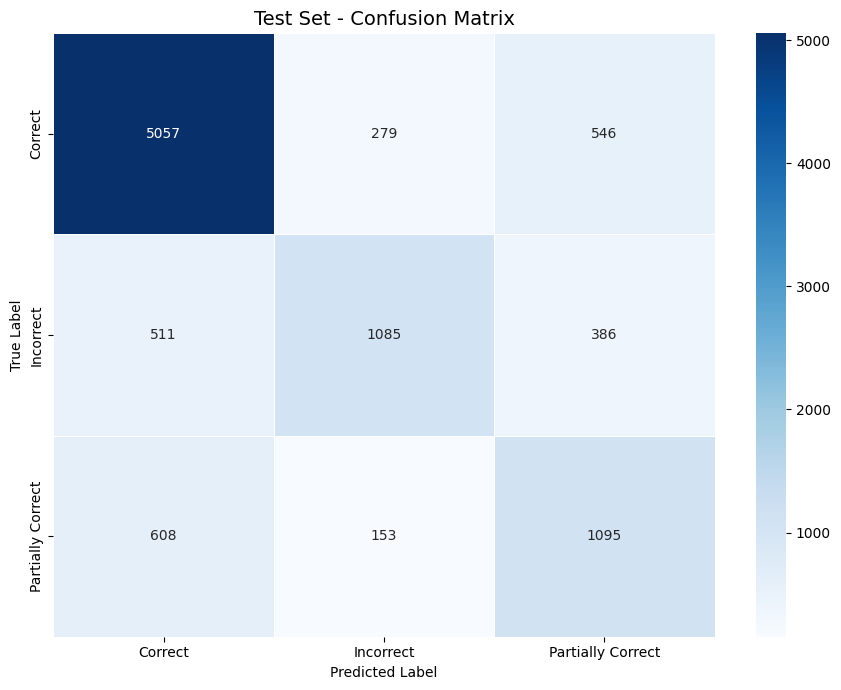

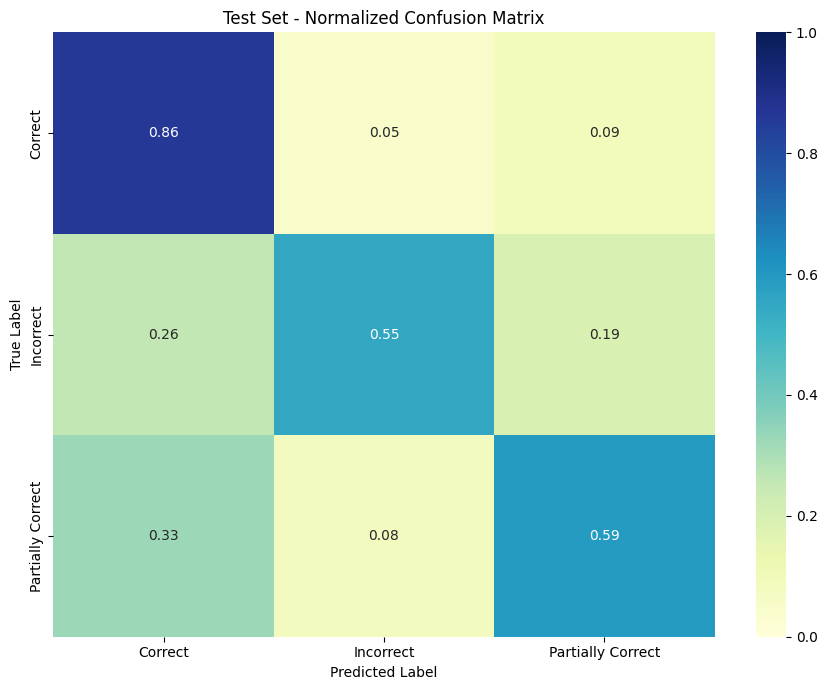


Evaluation completed successfully.
Saved: test_set_evaluation_metrics.csv


In [23]:

# ============================================================
# CELL 14: COMPREHENSIVE TEST SET EVALUATION
# ============================================================

import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    log_loss,
    top_k_accuracy_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# 1. Model evaluation
# ------------------------------------------------------------

test_metrics, test_logits, test_true = evaluate(
    model, test_loader
)

test_probs = torch.softmax(
    torch.as_tensor(test_logits, dtype=torch.float32),
    dim=-1
).cpu().numpy()

test_preds = np.asarray(test_logits).argmax(axis=1)

test_true = np.asarray(test_true)

class_labels = list(range(NUM_LABELS))

# ------------------------------------------------------------
# 2. Classification report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST SET CLASSIFICATION REPORT")
print("=" * 70)

print(classification_report(
    test_true,
    test_preds,
    labels=class_labels,
    target_names=LABELS,
    digits=4,
    zero_division=0
))

# ------------------------------------------------------------
# 3. Classification metrics
# ------------------------------------------------------------

test_acc = accuracy_score(test_true, test_preds)

# Precision
test_macro_precision = precision_score(
    test_true, test_preds,
    average="macro",
    zero_division=0
)

test_weighted_precision = precision_score(
    test_true, test_preds,
    average="weighted",
    zero_division=0
)

# Recall
test_macro_recall = recall_score(
    test_true, test_preds,
    average="macro",
    zero_division=0
)

test_weighted_recall = recall_score(
    test_true, test_preds,
    average="weighted",
    zero_division=0
)

# F1-score
test_mf1 = f1_score(
    test_true, test_preds,
    average="macro",
    zero_division=0
)

test_wf1 = f1_score(
    test_true, test_preds,
    average="weighted",
    zero_division=0
)

# Balanced accuracy
test_bal_acc = balanced_accuracy_score(
    test_true, test_preds
)

# Agreement metrics
test_kap = cohen_kappa_score(
    test_true, test_preds
)

test_mcc = matthews_corrcoef(
    test_true, test_preds
)

# ------------------------------------------------------------
# 4. Probability-based metrics
# ------------------------------------------------------------

try:
    if NUM_LABELS == 2:
        test_auc = roc_auc_score(
            test_true,
            test_probs[:, 1]
        )
    else:
        test_auc = roc_auc_score(
            test_true,
            test_probs,
            multi_class="ovr",
            average="macro",
            labels=class_labels
        )
except ValueError as e:
    print("ROC-AUC calculation warning:", e)
    test_auc = float("nan")

try:
    test_ll = log_loss(
        test_true,
        test_probs,
        labels=class_labels
    )
except ValueError as e:
    print("Log Loss calculation warning:", e)
    test_ll = float("nan")

try:
    test_top2 = top_k_accuracy_score(
        test_true,
        test_probs,
        k=min(2, NUM_LABELS),
        labels=class_labels
    )
except ValueError as e:
    print("Top-K accuracy warning:", e)
    test_top2 = float("nan")

# ------------------------------------------------------------
# 5. Print complete metric summary
# ------------------------------------------------------------

test_results = {
    "Accuracy": test_acc,
    "Macro Precision": test_macro_precision,
    "Weighted Precision": test_weighted_precision,
    "Macro Recall": test_macro_recall,
    "Weighted Recall": test_weighted_recall,
    "Macro F1": test_mf1,
    "Weighted F1": test_wf1,
    "Balanced Accuracy": test_bal_acc,
    "Cohen's Kappa": test_kap,
    "MCC": test_mcc,
    "ROC-AUC (Macro)": test_auc,
    "Log Loss": test_ll,
    "Top-2 Accuracy": test_top2
}

print("\n" + "=" * 70)
print("FINAL TEST SET PERFORMANCE")
print("=" * 70)

for metric, value in test_results.items():
    print(f"{metric:<25}: {value:.4f}")

# ------------------------------------------------------------
# 6. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    test_true,
    test_preds,
    labels=class_labels
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABELS,
    yticklabels=LABELS,
    linewidths=0.5
)

plt.title("Test Set - Confusion Matrix", fontsize=14)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Normalized confusion matrix
# ------------------------------------------------------------

cm_norm = confusion_matrix(
    test_true,
    test_preds,
    labels=class_labels,
    normalize="true"
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=LABELS,
    yticklabels=LABELS,
    vmin=0,
    vmax=1
)

plt.title("Test Set - Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Save evaluation results
# ------------------------------------------------------------

test_results_df = pd.DataFrame(
    [test_results]
)

test_results_df.to_csv(
    "test_set_evaluation_metrics.csv",
    index=False
)

print("\nEvaluation completed successfully.")
print("Saved: test_set_evaluation_metrics.csv")


In [15]:
# ============================================================
# CELL 15: Per-Class Metrics
# ============================================================
p, r, f, sup = precision_recall_fscore_support(
    test_true, test_preds, labels=list(range(NUM_LABELS)), zero_division=0
)
per_class = pd.DataFrame({"label": LABELS, "precision": p, "recall": r, "f1": f, "support": sup})
print(per_class.round(4))
per_class.to_csv(OUTPUT_DIR / "per_class_metrics.csv", index=False)

               label  precision  recall      f1  support
0            Correct     0.8188  0.8597  0.8388     5882
1          Incorrect     0.7152  0.5474  0.6202     1982
2  Partially Correct     0.5402  0.5900  0.5640     1856


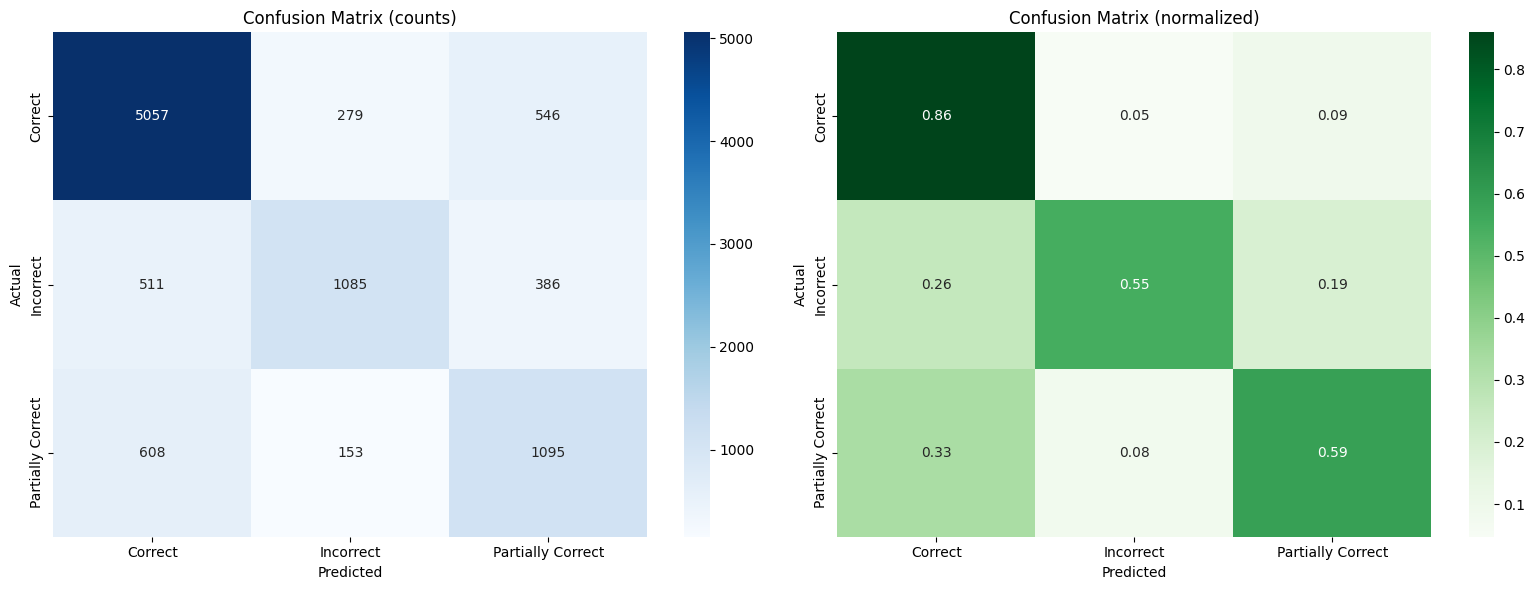

In [16]:
# ============================================================
# CELL 16: Confusion Matrix Visualization
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns
cm      = confusion_matrix(test_true, test_preds, labels=list(range(NUM_LABELS)))
cm_norm = cm.astype("float") / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[0])
axes[0].set_title("Confusion Matrix (counts)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens",
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[1])
axes[1].set_title("Confusion Matrix (normalized)")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

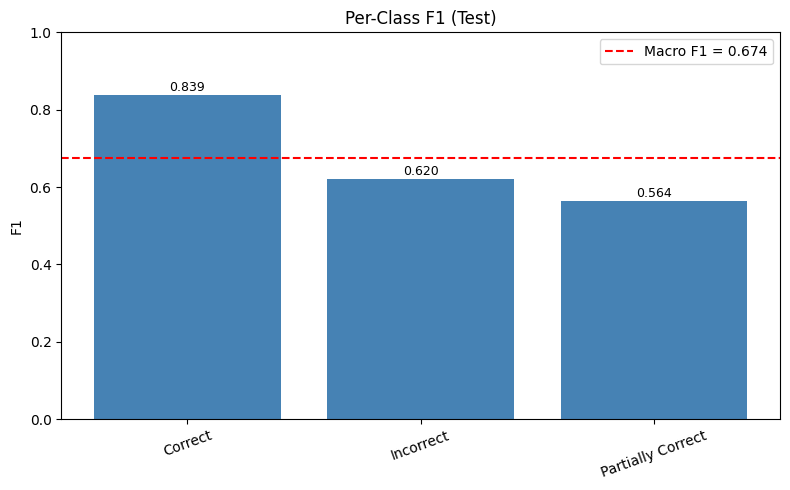

In [17]:
# ============================================================
# CELL 17: Per-Class F1 Bar Chart
# ============================================================
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(per_class["label"], per_class["f1"], color="steelblue")
ax.axhline(test_mf1, color="red", linestyle="--", label=f"Macro F1 = {test_mf1:.3f}")
ax.set_ylim(0, 1); ax.set_ylabel("F1"); ax.set_title("Per-Class F1 (Test)")
ax.tick_params(axis="x", rotation=20)
for b, v in zip(bars, per_class["f1"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "per_class_f1.png", dpi=300, bbox_inches="tight")
plt.show()

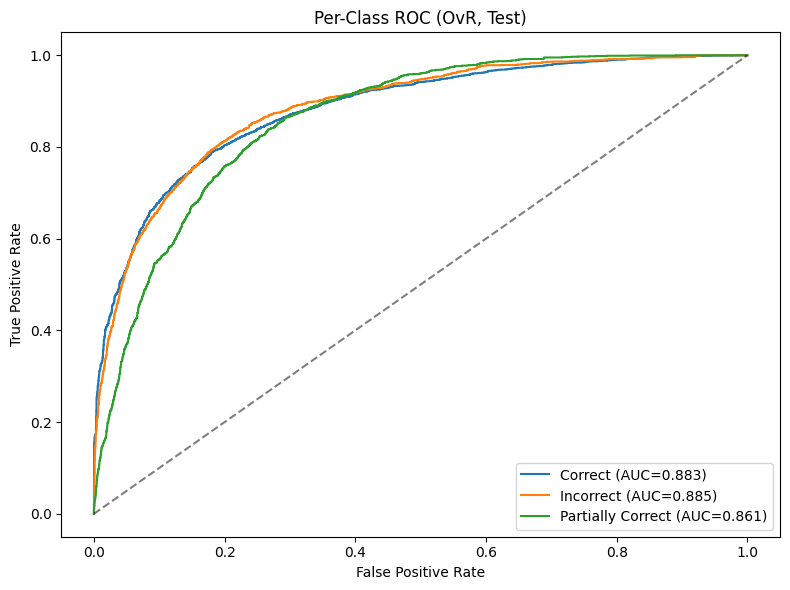

In [18]:
# ============================================================
# CELL 18: ROC Curves (One-vs-Rest)
# ============================================================
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_bin = label_binarize(test_true, classes=list(range(NUM_LABELS)))
fig, ax = plt.subplots(figsize=(8, 6))
for i, lbl in enumerate(LABELS):
    if y_bin[:, i].sum() == 0: continue
    fpr, tpr, _ = roc_curve(y_bin[:, i], test_probs[:, i])
    ax.plot(fpr, tpr, label=f"{lbl} (AUC={auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("Per-Class ROC (OvR, Test)"); ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

Expected Calibration Error (ECE): 0.1034


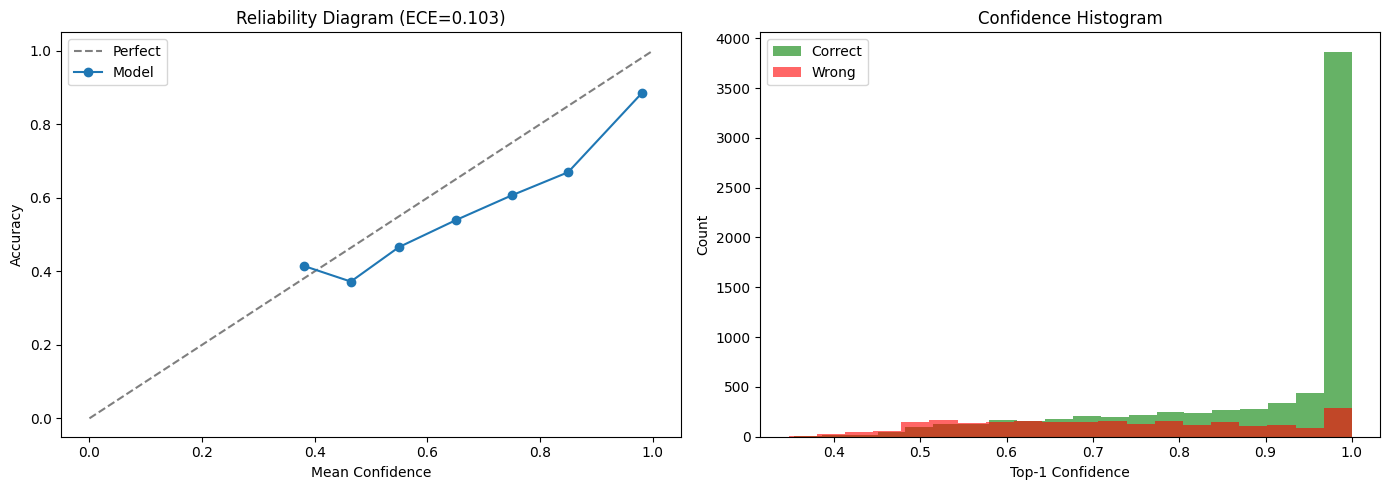

In [19]:
# ============================================================
# CELL 19: Calibration Analysis (ECE + Reliability Diagram)
# ============================================================
confidences = test_probs.max(axis=1)
correct = (test_preds == test_true).astype(int)
n_bins, edges = 10, np.linspace(0, 1, 11)
ece = 0.0
pts = []
for i in range(n_bins):
    m = (confidences >= edges[i]) & (confidences < edges[i+1])
    if m.sum() == 0: continue
    mc, ma = confidences[m].mean(), correct[m].mean()
    ece += m.sum() / len(confidences) * abs(mc - ma)
    pts.append(((edges[i]+edges[i+1])/2, mc, ma))

print(f"Expected Calibration Error (ECE): {ece:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if pts:
    _, cs, acs = zip(*pts)
    axes[0].plot([0,1], [0,1], "k--", alpha=0.5, label="Perfect")
    axes[0].plot(cs, acs, "o-", label="Model")
    axes[0].set_xlabel("Mean Confidence"); axes[0].set_ylabel("Accuracy")
    axes[0].set_title(f"Reliability Diagram (ECE={ece:.3f})"); axes[0].legend()

axes[1].hist(confidences[correct==1], bins=20, alpha=0.6, color="green", label="Correct")
axes[1].hist(confidences[correct==0], bins=20, alpha=0.6, color="red",   label="Wrong")
axes[1].set_xlabel("Top-1 Confidence"); axes[1].set_ylabel("Count")
axes[1].set_title("Confidence Histogram"); axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "calibration.png", dpi=300, bbox_inches="tight")
plt.show()

  language  samples  accuracy  macro_f1  weighted_f1  cohen_kappa
0       EN     1614    0.7577    0.6858       0.7561       0.5410
1       HI     1626    0.7645    0.6481       0.7533       0.4963
2    HI-EN     1620    0.7179    0.6726       0.7138       0.5384
3       NE     1626    0.7491    0.6803       0.7455       0.5562
4       TA     1620    0.7333    0.6435       0.7331       0.5030
5       TE     1614    0.7447    0.6535       0.7346       0.5019


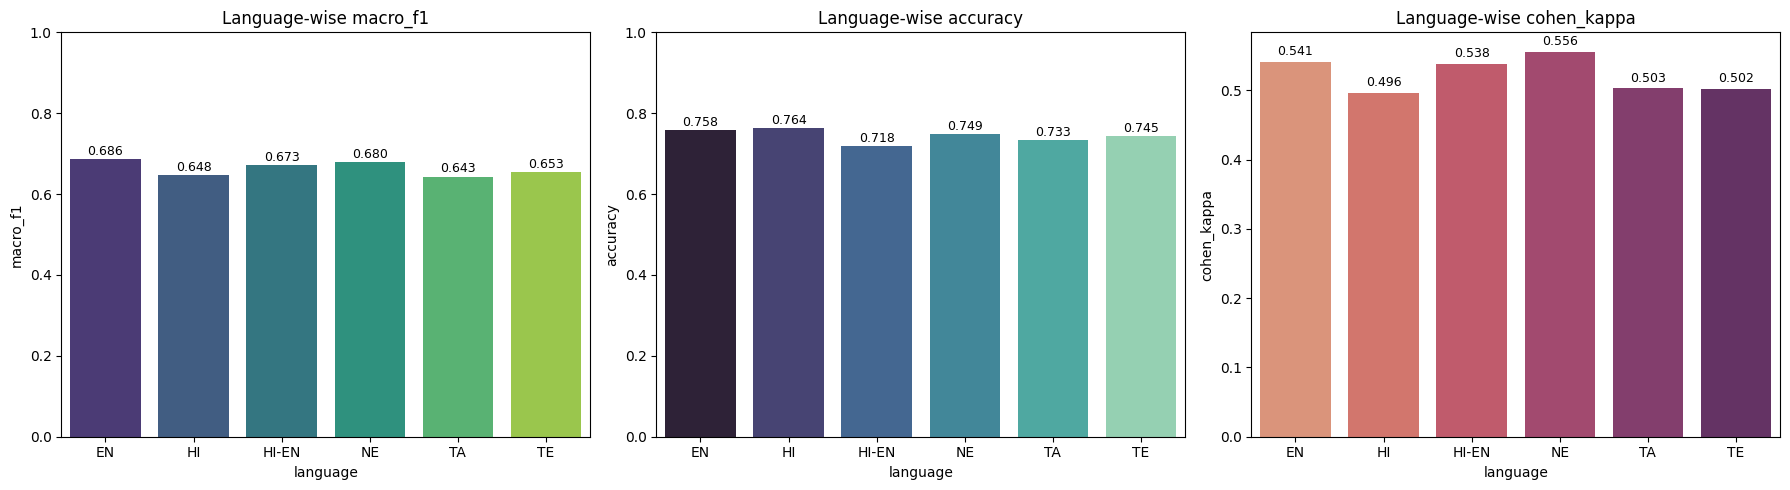

In [20]:
# ============================================================
# CELL 20: Language-Wise Metrics
# ============================================================
def grouped_metrics(df, group_col):
    rows = []
    for g in sorted(df[group_col].dropna().astype(str).unique()):
        mask = df[group_col].astype(str).to_numpy() == g
        yt, yp = test_true[mask], test_preds[mask]
        if len(yt) == 0: continue
        rows.append({
            group_col: g, "samples": int(mask.sum()),
            "accuracy": accuracy_score(yt, yp),
            "macro_f1": f1_score(yt, yp, labels=list(range(NUM_LABELS)),
                                 average="macro", zero_division=0),
            "weighted_f1": f1_score(yt, yp, labels=list(range(NUM_LABELS)),
                                    average="weighted", zero_division=0),
            "cohen_kappa": cohen_kappa_score(yt, yp),
        })
    return pd.DataFrame(rows)

lang_df = grouped_metrics(test_df, "language")
print(lang_df.round(4))
lang_df.to_csv(OUTPUT_DIR / "language_wise_results.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, cmap in zip(axes, ["macro_f1", "accuracy", "cohen_kappa"],
                        ["viridis", "mako", "flare"]):
    sns.barplot(data=lang_df, x="language", y=col, ax=ax, palette=cmap)
    ax.set_title(f"Language-wise {col}")
    if col != "cohen_kappa": ax.set_ylim(0, 1)
    for i, v in enumerate(lang_df[col]):
        ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "language_wise.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:
# ============================================================
# CELL 21: Domain / Difficulty / Fact-Type / Model Wise Metrics
# ============================================================
# (the original notebook looked for "domain_ref" etc., which do not exist after the merge,
#  so those tables were silently skipped — fixed here)
for col in ["domain", "difficulty", "fact_type", "model_name"]:
    if col in test_df.columns:
        df_g = grouped_metrics(test_df, col)
        print(f"\n{col}:")
        print(df_g.round(4))
        df_g.to_csv(OUTPUT_DIR / f"{col}_wise_results.csv", index=False)


domain:
       domain  samples  accuracy  macro_f1  weighted_f1  cohen_kappa
0     Culture      180    0.8667    0.7210       0.8635       0.5882
1   Economics      162    0.7222    0.6551       0.7146       0.4997
2   Education      150    0.7000    0.5401       0.6885       0.3367
3   Geography      162    0.7654    0.6921       0.7586       0.5539
4  Government      162    0.7901    0.6739       0.7973       0.5296
5      Health      168    0.7202    0.6311       0.7249       0.4815
6     History      156    0.6731    0.6333       0.6757       0.4355
7     Science      168    0.7440    0.6722       0.7391       0.5758
8      Sports      138    0.7174    0.6558       0.7154       0.5051
9  Technology      168    0.8512    0.8433       0.8504       0.7307

difficulty:
  difficulty  samples  accuracy  macro_f1  weighted_f1  cohen_kappa
0       Hard      300    0.7067    0.6596       0.7000       0.4845
1        Low      678    0.7729    0.7036       0.7695       0.5626
2     Medium   

In [22]:
# ============================================================
# CELL 22: Save Predictions, Metrics, and Splits
# ============================================================
pred_df = test_df[[
    "response_id", "question_id", "language", "model_name",
    "correctness_label", "question", "ground_truth", "response",
]].copy()
pred_df["predicted_label"] = label_encoder.inverse_transform(test_preds)
pred_df["confidence"] = test_probs.max(axis=1)
pred_df["correct_prediction"] = (pred_df["correctness_label"] == pred_df["predicted_label"])
for i, lbl in enumerate(LABELS):
    pred_df[f"prob_{lbl}"] = test_probs[:, i]

pred_df.to_csv(OUTPUT_DIR / "test_predictions_full.csv", index=False)
pred_df[~pred_df["correct_prediction"]].to_csv(OUTPUT_DIR / "test_errors.csv", index=False)

metrics_output = {
    "model": "Hybrid Match-CNN (multi-kernel TextCNN encoder + soft-match + overlap features)",
    "task": f"{NUM_LABELS}-class correctness classification",
    "train_rows": len(train_df), "dev_rows": len(dev_df), "test_rows": len(test_df),
    "labels": LABELS, "seed": SEED,
    "tokenizer_mode": TOKENIZER_MODE, "pretrained_name": PRETRAINED_NAME, "embedding_rows": VOCAB_N,
    "hyperparameters": {
        "max_q_len": MAX_Q_LEN, "max_g_len": MAX_G_LEN, "max_r_len": MAX_R_LEN,
        "num_filters": NUM_FILTERS, "kernel_sizes": KERNEL_SIZES,
        "match_hidden": MATCH_HIDDEN, "cls_hidden": CLS_HIDDEN,
        "dropout": DROPOUT, "emb_dropout": EMB_DROPOUT,
        "use_match": USE_MATCH, "use_hand": USE_HAND,
        "lr": LEARNING_RATE, "emb_lr": EMB_LR, "epochs_max": EPOCHS, "patience": PATIENCE,
        "select_metric": SELECT_METRIC, "class_weight_mode": CLASS_WEIGHT_MODE,
        "train_batch_size": TRAIN_BATCH_SIZE,
    },
    "best_dev_score": float(best_score),
    "test_metrics": {
        "accuracy": float(test_acc),
        "macro_f1": float(test_mf1),
        "weighted_f1": float(test_wf1),
        "cohen_kappa": float(test_kap),
        "mcc": float(test_mcc),
        "roc_auc_macro": float(test_auc) if not np.isnan(test_auc) else None,
        "log_loss": float(test_ll) if not np.isnan(test_ll) else None,
        "top2_accuracy": float(test_top2) if not np.isnan(test_top2) else None,
        "ece": float(ece),
    },
    "per_class": per_class.to_dict(orient="records"),
}
with open(OUTPUT_DIR / "test_metrics_full.json", "w", encoding="utf-8") as fh:
    json.dump(metrics_output, fh, indent=4)

train_df.to_csv(OUTPUT_DIR / "train_split.csv", index=False)
dev_df.to_csv(OUTPUT_DIR / "dev_split.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_split.csv", index=False)

print("\nAll artifacts saved to:", OUTPUT_DIR)


All artifacts saved to: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\results\cnn_v2_full_dataset
